**Articles for next week.**

1. https://www.mdpi.com/2072-4292/14/19/4978 
2. https://isprs-annals.copernicus.org/articles/V-3-2020/803/2020/isprs-annals-V-3-2020-803-2020.pdf 


# **Image classification using machine learning: an example**

In this exercise we will use Sentinel-2 images to make land cover classification following Land Cover Classification System (LCCS) defined by the UN Food and Agriculture Organization (FAO). The image contains 9 bands (2,3,4,8,5,6,7,11,12). Additionally, training data of each class is also provided as raster data. We will go through the major steps to use the training data, train the model, deploy it and evaluate.

**Import the necessary packages.**

In [1]:
import geopandas as gpd, numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
import xarray as xr
import os
#os.environ["PROJ_DATA"] ="/home/migi/miniconda3/envs/tfdml/lib/python3.10/site-packages/pyproj/proj_dir/share/proj"
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

**Know in which folder you are working.**

In [2]:
print(os.getcwd())

/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_5


**Define the image data file and the training data file**

Give the full file address if they are not located in the workind directory.

In [3]:
img='S2_image.tif'
lable='training_data.tif'

**Read the datasets and explore their metadata.**

Why do we do the transpose()?

What is the spatial resolution of the image?

What is the spatial reference system of the image?

What is the data type of the image?

In [4]:
im=xr.open_dataset(img)
im=im['band_data'].transpose('y','x','band')
im

<xarray.DataArray 'band_data' (y: 676, x: 922, band: 9)> Size: 22MB
[5609448 values with dtype=float32]
Coordinates:
  * y            (y) float64 5kB 9.295e+06 9.295e+06 ... 9.288e+06 9.288e+06
  * x            (x) float64 7kB 4.762e+05 4.762e+05 ... 4.854e+05 4.854e+05
  * band         (band) int64 72B 1 2 3 4 5 6 7 8 9
    spatial_ref  int64 8B ...
Attributes:
    AREA_OR_POINT:  Area

In [5]:
im.rio.resolution()

(10.00457646420825, -10.005985059171982)

In [6]:
#Print the minimum and maximum values of the image bands
print(im.min(dim=['x','y']).data,im.max(dim=['x','y']).data)

[211.5 403.5 238.5 322.5 644.5 424.  438.  176.  126. ] [4166.  3818.  3150.  5110.  4457.  4479.  5104.  5480.5 5082. ]


**Visualize the image data**

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.10575..2.083].


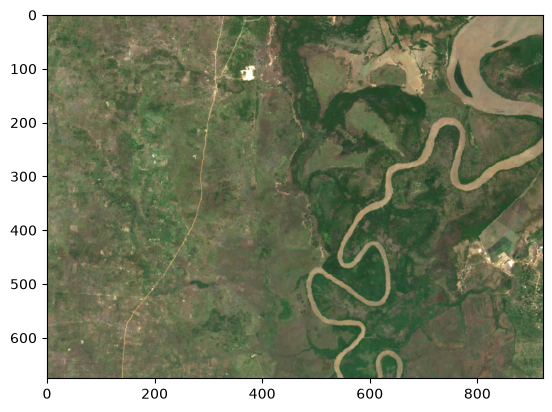

In [7]:
plt.imshow(im[:,:,:3]/2000)# The division by a value lower than the maximum is to make the image brighter

**Compute and visualize the histogram of each band of the image.**

Band 0 min and max: 211.5 4166.0
Band 1 min and max: 403.5 3818.0
Band 2 min and max: 238.5 3150.0
Band 3 min and max: 322.5 5110.0


KeyboardInterrupt: 

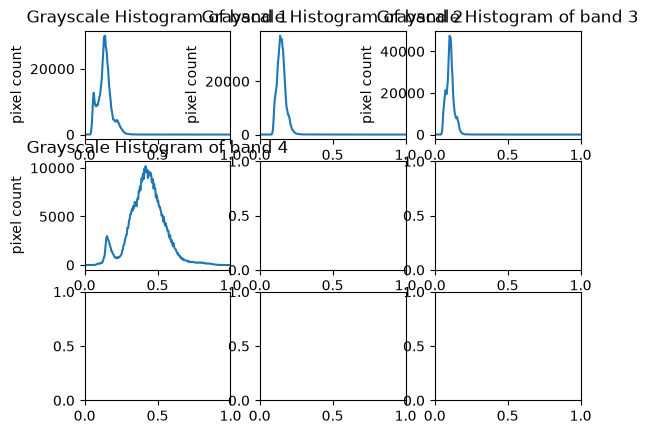

In [ ]:
fig, axes = plt.subplots(3, 3)
plt.rcParams["figure.figsize"] = (20,20)

lak=0
for numx in range(3):
    for numy in range(3):
        arr=np.array(im[:,:,lak].load()/im.max())#
        print('Band',lak,'min and max:',im[:,:,lak].min().data,im[:,:,lak].max().data)
        histogram, bin_edges = np.histogram(arr, bins=256, range=(0, 1))
        axes[numx,numy].set_title(f"Grayscale Histogram of band {lak+1}")
        axes[numx,numy].set_xlabel("grayscale value\n")
        axes[numx,numy].set_ylabel("pixel count")
        axes[numx,numy].set_xlim([0.0, 1.0])  # <- named arguments do not work here
        axes[numx,numy].plot(bin_edges[0:-1], histogram)  # <- or here
        #axes[numx,numy].label_outer()
        #break
        lak=lak+1

**Compute and display the correlation heatmap between the spectral bands.**

In [ ]:
data=im.data.reshape((im.shape[0]*im.shape[1],im.shape[2]))
print(data.shape)
data=pd.DataFrame(data)
corr=data.corr(numeric_only=True)

# Print correlation matrix
#print(corr)

# Set figure size (width=8, height=6 in inches)
plt.figure(figsize=(16, 12))
# Plot correlation heatmap
sns.heatmap(corr, cmap="YlGnBu", annot=True)

# Display heatmap
plt.show()

**Read the training (labled) data and explore.**

In [ ]:
lab=xr.open_dataset(lable)
#lab=lab['tr_data'].transpose('x','y','band')
lab=lab['band_data'].transpose('y','x','band')#'x','y','band')
lab.shape, np.unique(lab)#Get the shape and the unique class values. Notice that 0 is for the areas not included in the training data

In [ ]:
lab=lab.where(lab>0) # Consider only the training pixels and masked out the rest

**Define the response variable**

The land cover class names as defined by FAO are given below. These classes have also numerical codes. We hereby simplify the names to just one word each for use in this exercise. Both original name and the shorted name,are given below. The numerical codes are already used in the training dataset.

In [ ]:
class_names=['Tree cover', 'Shrubland','Grassland', 'Cropland','Built-up','Bare / sparse vegetation',  'Permanent water bodies', 
           'Herbaceous wetland', 'Mangroves', 'Mosse and lichen']
classnames=['Tree cover', 'Shrubland','Grassland', 'Cropland','Built-up','Baren', 'Water', 
           'Wetland', 'Mangroves', 'Mosses']
classnames=np.array(classnames)
classes=np.unique(lab)[:-1]
classnames,classes

**Compute and plot the number of training pixels for each class.**

In [ ]:
values, counts = np.unique(lab.values, return_counts=True)
labels = [str(v.astype('uint8')) for v in values]
plt.bar(labels[:-1], counts[:-1])
plt.xlabel("Classes")
plt.ylabel("Count")
plt.title("Counts per Class")
plt.show()

**Visualize the training data**

In [ ]:
plt.imshow(lab,cmap="tab10")
plt.colorbar(label="Class IDs") 

**Get the indices of the training data with valid class value.**

In [ ]:
indices=np.argwhere(lab[:,:,0].values > 0)
indices.shape

**Extract the Features/predictors, i.e. X, and the dependent class labels, i.e. y.**

In [ ]:
y=[lab[dat[0],dat[1],:].data.astype('uint8')[0] for dat in indices] 
X=[im[dat[0],dat[1],:].data for dat in indices] 
len(y),len(X)

**Scale the data**

In [ ]:
#X=(X-X.mean())/X.std() #Can also be tried with MinMax scaler
scaler = StandardScaler()
X = scaler.fit_transform(X)

**Data preparation for the machine learning**

Remember that machine learning models such as Random Forest (RF), Support Vector Machine (SVM), KNN, etc. do not utilize the spatial pattern and texture. The data is therefore fed into these models as tabular data. In Python the **Pandas DataFrame** gives the best tabular data model where features are organised as columns and samples are organised as rows. We will therefore create a DataFrame with r number of rows (r=number training pixels) and c number of columns (c=number of features or predictors or spectral bands in this case). 

In [ ]:
features=['B2','B3','B4','B8','B5','B6','B7','B11','B12']#The 9 bands of the S2 image
df=pd.DataFrame(X,columns=features)
df.shape

In [ ]:
df.head()

**Add the response variable, class, to the dataframe as one column.**

In [ ]:
df['class'] = y
print(df.shape)
df.head()

**Encoding categorical variables**

We use label encoder to encode the class values to values from 0 to the number of the classes.

In [ ]:
le = LabelEncoder()#Define the encoder
encoded = le.fit(classes)#Fit the encoder to the numerical class names
y_en=encoded.fit_transform(df['class'])#Apply to the classes
df['class_en'] = y_en
print(y_en.shape,  df['class_en'].shape, df.shape)
df.head()

**Data Splitting**

We split the training dataset into training and  test sets, with 80% and 20% respectively. The splitting is done by selecting the pixels randomly.

In [ ]:
df['is_train'] = np.random.uniform(0, 1, len(df)) <= .80
train, test = df[df['is_train']==True], df[df['is_train']==False]
features = df.columns[:-3]
features,df.columns

**Define the model**

We define a SVM model with some randomly assigned and some default hyperparameters.

In [ ]:
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, verbose=False)#,max_iter=-1,class_weight='balanced')

**Training the SVM model.**

In [ ]:
svm=svm_model.fit(train[features], train['class_en'])

**Deploy on the test dataset to evaluate the model**

In [ ]:
y_pred=svm.predict(test[features])
y_true=test['class_en']

**Compute the confusion matrix based on the test data**

In [ ]:
# Calculate accuracy
# Compute metrics in percentage
accuracy = accuracy_score(y_true, y_pred) * 100
precision = precision_score(y_true, y_pred, average='macro') * 100
recall = recall_score(y_true, y_pred, average='macro') * 100
f1 = f1_score(y_true, y_pred, average='macro') * 100

print(f"Accuracy: {accuracy:.2f}%")
print(f"Precision: {precision:.2f}%")
print(f"Recall: {recall:.2f}%")
print(f"F1-score: {f1:.2f}%")

In [ ]:
cm=pd.crosstab(y_true, y_pred, rownames=['actual'], colnames=['preds'])
# Plot confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix\nAccuracy: {accuracy:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Compute and plot the different accuracy metrix.**

In [ ]:
# Compute Producer's Accuracy (PA) and User's Accuracy (UA)
PA = np.diag(cm) / np.sum(cm, axis=1) * 100  # row-wise
UA = np.diag(cm) / np.sum(cm, axis=0) * 100  # column-wise

#print("Producer's Accuracy (%):", PA)
#print("User's Accuracy (%):", UA)

# Plot side by side
classcodes = [f'{classnames[i]}' for i in range(len(PA))]
x = np.arange(len(classcodes))
width = 0.35

plt.figure(figsize=(10,6))
plt.bar(x - width/2, PA, width, label="Producer's Accuracy", color='skyblue')
plt.bar(x + width/2, UA, width, label="User's Accuracy", color='salmon')
plt.ylim(0, 100)
plt.ylabel('Percentage (%)')
plt.title("Producer's and User's Accuracy per Class")
plt.xticks(x, classcodes)
plt.legend()

# Add labels on top of bars
for i in range(len(PA)):
    plt.text(i - width/2, PA[i] + 2, f"{PA[i]:.1f}%", ha='center')
    plt.text(i + width/2, UA[i] + 2, f"{UA[i]:.1f}%", ha='center')

plt.show()

In [ ]:
# Plot all metrics as a bar chart
metrics = [accuracy, precision, recall, f1]
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-score']

plt.figure(figsize=(7,5))
sns.barplot(x=metric_names, y=metrics, palette="viridis")
plt.ylim(0, 100)
plt.ylabel('Percentage (%)')
plt.title('Classification Metrics in Percentage')
for i, v in enumerate(metrics):
    plt.text(i, v + 2, f"{v:.2f}%", ha='center')
plt.show()

**Prepare an entire image for deploying the trained model**

First visulize the image. Then flatten the dataset to make it ready for the prediction.

In [ ]:
# --- 2. Flatten image for classification ---
n_samples, n_bands = im.shape[0] * im.shape[1], im.shape[2]
flat_pixels = im.data.reshape(n_samples, n_bands)
flat_pixels.shape

**Scale the dataset as well**

In [ ]:
scaler = StandardScaler()
flat_pixels = scaler.fit_transform(flat_pixels)

**Convert the dataset to Data Frame**


In [ ]:
flat_pixels=pd.DataFrame(flat_pixels,columns=features)
flat_pixels.head()

**Deploy the model to classify the entire image**

In [ ]:
# --- 4. Predict land cover for all pixels ---
predicted = svm.predict(flat_pixels)
predicted.shape

**Reshape the classification result back to shape of the image**

In [ ]:
classified_map = predicted.reshape(im.shape[0], im.shape[1])
classified_map.shape

In [ ]:
classes

In [ ]:
#classes=classes[1:]

In [ ]:
classes[np.unique(classified_map)], classes

In [ ]:
from matplotlib.colors import ListedColormap
#Define color for each class
colors = [
    "green", "yellow", "lightgreen", "purple", "orange",
    "red", "pink", "blue", "gray", "darkgreen"
]
cmap = ListedColormap(colors)
# Show image
im = plt.imshow(classified_map, cmap=cmap)

# Add colorbar with class labels
cbar = plt.colorbar(im, ticks=np.arange(len(classnames)))
cbar.ax.set_yticklabels(classnames)  # replace indices with names
plt.title("Map of the predicted classes")
plt.axis("off")
plt.show()

**Compute and plot the histogram of the predicted classes.**

In [ ]:
values, counts = np.unique(classes[classified_map], return_counts=True)
labels = [classnames[v] for v in range(len(values))]
plt.bar(labels, counts)
plt.xlabel("Classes")
plt.ylabel("Count")
plt.title("Counts per Class")
plt.show()

In [ ]:
#Try with NDVI added
#Try with scaling the dataset

In [ ]:
# Create a pipeline: scaling + SVM
model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma='scale'))
# Perform 5-fold cross-validation
scores = cross_val_score(model,train[features], train['class_en'], cv=5, scoring='accuracy')

print("Cross-validation scores:", scores)
print("Mean accuracy:", np.mean(scores))
print("Std deviation:", np.std(scores))